# Face inversion: data, alignment and training

Downloads a 500-identity subset of VGGFace2, aligns every face to 112x112 with MTCNN, trains the three ResNet-18 models (baseline, rotation-augmented, C4-equivariant) and runs the first set of face tests.

Needs a GPU runtime, a Colab secret called `HF_Token`, and the dataset terms accepted at https://huggingface.co/datasets/ProgramComputer/VGGFace2. Everything is saved to `MyDrive/face_inversion`.

## Setup

In [ ]:
# escnn needs lie_learn installed first on python 3.13; facenet-pytorch without deps so it keeps colab's torch
!pip -q install git+https://github.com/AMLab-Amsterdam/lie_learn
!pip -q install escnn
!pip -q install --no-deps facenet-pytorch
import torch, escnn, facenet_pytorch
from escnn import gspaces
print("torch", torch.__version__, "| cuda", torch.cuda.is_available())
print("C4 gspace OK:", gspaces.rot2dOnR2(N=4))

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
torch 2.11.0+cu130 | cuda True
C4 gspace OK: C4_on_R2[(None, 4)]


In [ ]:
import os, subprocess
from google.colab import userdata
os.environ["HF_TOKEN"] = userdata.get("HF_Token")   # colab secret name
os.environ["BASE"] = "https://huggingface.co/datasets/ProgramComputer/VGGFace2/resolve/main/data"
os.makedirs("/content/vggface2", exist_ok=True)
!df -h /content | tail -1
!nvidia-smi --query-gpu=name,memory.total --format=csv

overlay         236G   18G  218G   8% /
name, memory.total [MiB]
Tesla T4, 15360 MiB


In [ ]:
# 200 means ok, 401/403 means the dataset terms are not accepted or the token is wrong
!curl -s -o /dev/null -w "HTTP %{http_code}\n" -L -H "Authorization: Bearer $HF_TOKEN" "$BASE/test_list.txt"

HTTP 200


## Download

In [ ]:
%%bash
# file lists and the test set (2 GB, 500 identities not in train)
set -e
cd /content/vggface2
curl -fsSL -H "Authorization: Bearer $HF_TOKEN" -o train_list.txt "$BASE/train_list.txt"
curl -fsSL -H "Authorization: Bearer $HF_TOKEN" -o test_list.txt "$BASE/test_list.txt"
wc -l train_list.txt test_list.txt
head -3 train_list.txt
curl -fsSL -H "Authorization: Bearer $HF_TOKEN" "$BASE/vggface2_test.tar.gz" | tar -xz
ls
du -sh .

 3141890 train_list.txt
  169396 test_list.txt
 3311286 total
n000002/0001_01.jpg
n000002/0002_01.jpg
n000002/0003_01.jpg
patterns.txt
test
test_list.txt
train
train_list.txt
5.3G	.


In [ ]:
# train subset: stream the 38 GB archive through tar and keep only the chosen identities
import collections
N_IDS, MIN_IMGS = 500, 300
counts = collections.Counter(l.split('/')[0] for l in open('/content/vggface2/train_list.txt') if l.strip())
chosen = sorted(i for i, c in counts.items() if c >= MIN_IMGS)[:N_IDS]
open('/content/vggface2/patterns.txt', 'w').writelines(f'*{i}/*\n' for i in chosen)
print(len(chosen), 'identities,', sum(counts[i] for i in chosen), 'images')
subprocess.run('cd /content/vggface2 && curl -fsSL -H "Authorization: Bearer $HF_TOKEN" "$BASE/vggface2_train.tar.gz" '
               '| tar -xz --wildcards -T patterns.txt', shell=True, check=True)
!du -sh /content/vggface2/*

500 identities, 206454 images
8.0K	/content/vggface2/patterns.txt
2.3G	/content/vggface2/test
3.3M	/content/vggface2/test_list.txt
2.9G	/content/vggface2/train
60M	/content/vggface2/train_list.txt


In [ ]:
# count downloaded images
!du -sh /content/vggface2/train /content/vggface2/test 2>/dev/null || du -sh /content/vggface2/*
import glob
tr = glob.glob('/content/vggface2/**/n*/*.jpg', recursive=True)
print(len(tr), 'images total')

2.9G	/content/vggface2/train
2.3G	/content/vggface2/test
375850 images total


In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
# keep a copy of the raw subset on drive
!df -h /content/drive | tail -1          # need about 5.5 GB free
!mkdir -p /content/drive/MyDrive/face_inversion
!tar -cf /content/drive/MyDrive/face_inversion/vggface2_subset.tar -C /content vggface2/train vggface2/test vggface2/train_list.txt vggface2/test_list.txt
!ls -lh /content/drive/MyDrive/face_inversion/

drive           236G   29G  208G  13% /content/drive
total 7.2G
drwx------ 2 root root 4.0K Nov  5 11:09 ckpt
-rw------- 1 root root 1.1M Nov  5 08:36 split.json
-rw------- 1 root root 2.4G Nov  5 08:20 vggface2_aligned112.tar
-rw------- 1 root root 4.8G Nov  5 13:26 vggface2_subset.tar


## Face alignment

This took several sessions on Colab (2 CPUs); the cell skips files that are already done. 357 images had no detectable face; they are listed in `failures.txt`.

In [ ]:
# mtcnn landmarks, then a similarity warp of the 5 points onto the arcface template
import os, glob, time, cv2, numpy as np
from tqdm.auto import tqdm
from facenet_pytorch import MTCNN
from torch.utils.data import Dataset, DataLoader

SRC, DST = '/content/vggface2', '/content/vggface2_aligned'
S, BATCH = 192, 256
LIMIT = None
REF = np.array([[38.2946, 51.6963], [73.5318, 51.5014], [56.0252, 71.7366],
                [41.5493, 92.3655], [70.7299, 92.2041]], np.float32)

paths = sorted(glob.glob(f'{SRC}/train/*/*.jpg') + glob.glob(f'{SRC}/test/*/*.jpg'))
dst_of = lambda p: p.replace(SRC, DST, 1)
todo = [p for p in paths if not os.path.exists(dst_of(p))][:LIMIT]
print(len(paths), 'images total,', len(todo), 'to align,', os.cpu_count(), 'CPUs')

class Letterbox(Dataset):
    def __len__(self): return len(todo)
    def __getitem__(self, i):
        img = cv2.cvtColor(cv2.imread(todo[i]), cv2.COLOR_BGR2RGB)
        h, w = img.shape[:2]; r = S / max(h, w)
        nh, nw = round(h * r), round(w * r)
        canvas = np.zeros((S, S, 3), np.uint8)
        canvas[:nh, :nw] = cv2.resize(img, (nw, nh))
        return canvas, img, r, i

collate = lambda b: (np.stack([x[0] for x in b]), [x[1] for x in b], [x[2] for x in b], [x[3] for x in b])
loader = DataLoader(Letterbox(), batch_size=BATCH, num_workers=os.cpu_count(), collate_fn=collate)
mtcnn = MTCNN(keep_all=True, min_face_size=40, device='cuda')

fails, t0 = [], time.time()
for canv, origs, rs, idx in tqdm(loader):
    boxes, probs, pts = mtcnn.detect(canv, landmarks=True)
    for b, lm, img, r, i in zip(boxes, pts, origs, rs, idx):
        if b is None: fails.append(todo[i]); continue
        k = int(np.argmax((b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])))
        M, _ = cv2.estimateAffinePartial2D(lm[k].astype(np.float32) / r, REF, method=cv2.LMEDS)
        if M is None: fails.append(todo[i]); continue
        out = cv2.warpAffine(img, M, (112, 112), borderValue=0)
        d = dst_of(todo[i]); os.makedirs(os.path.dirname(d), exist_ok=True)
        cv2.imwrite(d, cv2.cvtColor(out, cv2.COLOR_RGB2BGR), [cv2.IMWRITE_JPEG_QUALITY, 95])

os.makedirs(DST, exist_ok=True)
open(f'{DST}/failures.txt', 'a').writelines(p + '\n' for p in fails)
print(f'{len(todo) - len(fails)} aligned, {len(fails)} failed, {len(todo) / (time.time() - t0):.0f} img/s')

375703 aligned files


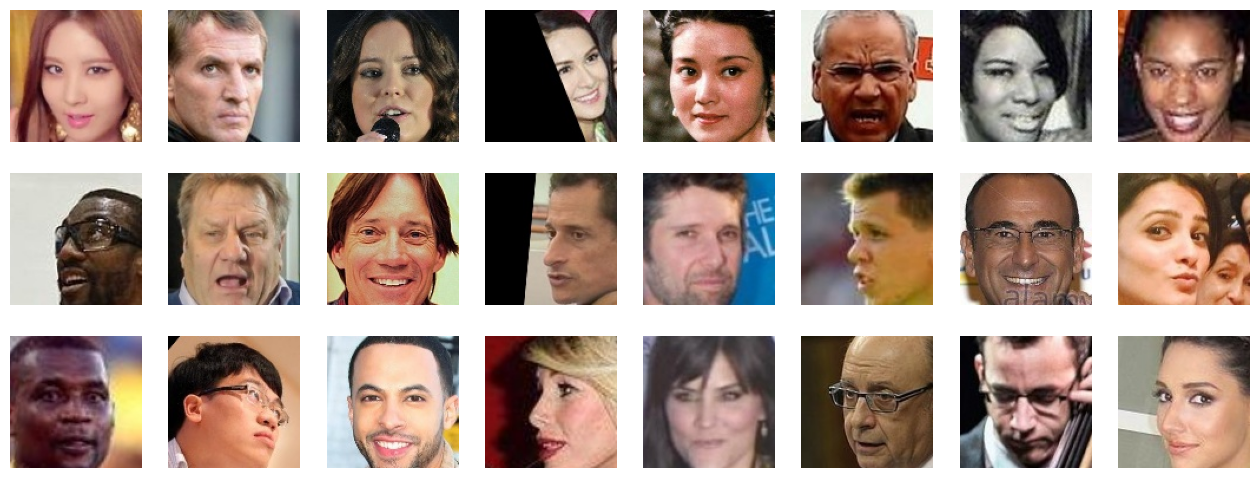

In [ ]:
# a few aligned faces
import random, matplotlib.pyplot as plt
done = glob.glob(f'{DST}/*/*/*.jpg'); print(len(done), 'aligned files')
fig, ax = plt.subplots(3, 8, figsize=(16, 6))
for a, p in zip(ax.flat, random.sample(done, min(24, len(done)))): a.imshow(plt.imread(p)); a.axis('off')

In [ ]:
# save the aligned faces to drive
from google.colab import drive; drive.mount('/content/drive')
!tar -cf /content/drive/MyDrive/face_inversion/vggface2_aligned112.tar -C /content vggface2_aligned
!ls -lh /content/drive/MyDrive/face_inversion/
drive.flush_and_unmount()

Mounted at /content/drive
total 7.2G
-rw------- 1 root root 2.4G Nov  5 08:20 vggface2_aligned112.tar
-rw------- 1 root root 4.8G Nov  5 07:20 vggface2_subset.tar


## Training

Restart here after a runtime reset: restore the aligned faces, rebuild the split, and checkpoints resume from Drive.

In [ ]:
# restore aligned faces from drive
import os
from google.colab import drive; drive.mount('/content/drive')
if not os.path.isdir('/content/vggface2_aligned/train'):
    !tar -xf /content/drive/MyDrive/face_inversion/vggface2_aligned112.tar -C /content
!nvidia-smi --query-gpu=name,memory.used,memory.total --format=csv

Mounted at /content/drive
name, memory.used [MiB], memory.total [MiB]
Tesla T4, 3 MiB, 15360 MiB


In [ ]:
# 90/10 train/val split within each identity, all images cached on the gpu as uint8
import glob, json, random, numpy as np, torch, cv2
from tqdm.auto import tqdm
from torch.utils.data import Dataset, DataLoader

ROOT = '/content/vggface2_aligned/train'
ids = sorted(d for d in os.listdir(ROOT) if d.startswith('n'))
rng = random.Random(0); tr, va = [], []
for lab, i in enumerate(ids):
    fs = sorted(glob.glob(f'{ROOT}/{i}/*.jpg')); rng.shuffle(fs)
    nv = max(1, len(fs) // 10)                       # 10% of each identity for val
    va += [(f, lab) for f in fs[:nv]]; tr += [(f, lab) for f in fs[nv:]]
json.dump({'ids': ids, 'val': [f for f, _ in va]}, open('/content/drive/MyDrive/face_inversion/split.json', 'w'))
print(len(ids), 'identities |', len(tr), 'train |', len(va), 'val')

class Raw(Dataset):
    def __init__(s, items): s.items = items
    def __len__(s): return len(s.items)
    def __getitem__(s, k):
        return torch.from_numpy(cv2.cvtColor(cv2.imread(s.items[k][0]), cv2.COLOR_BGR2RGB)).permute(2, 0, 1)

def to_gpu(items):
    X = torch.empty((len(items), 3, 112, 112), dtype=torch.uint8, device='cuda'); n = 0
    for x in tqdm(DataLoader(Raw(items), batch_size=1024, num_workers=os.cpu_count())):
        X[n:n + len(x)] = x.cuda(non_blocking=True); n += len(x)
    return X, torch.tensor([l for _, l in items], device='cuda')

Xtr, Ytr = to_gpu(tr); Xva, Yva = to_gpu(va)
print(f'GPU cache {(Xtr.numel() + Xva.numel()) / 1e9:.1f} GB')

500 identities | 185946 train | 20414 val
GPU cache 7.8 GB


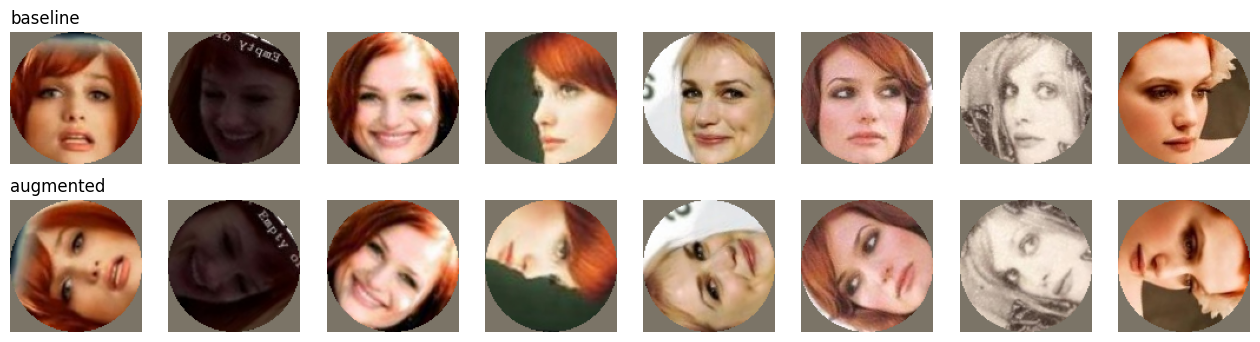

In [ ]:
# preprocessing: normalise, random flip, random rotation (augmented model only), circular mask for every model
import math, torch.nn.functional as F, matplotlib.pyplot as plt
MEAN = torch.tensor([0.485, 0.456, 0.406], device='cuda').view(1, 3, 1, 1) * 255
STD  = torch.tensor([0.229, 0.224, 0.225], device='cuda').view(1, 3, 1, 1) * 255
yy, xx = torch.meshgrid(torch.arange(112, device='cuda'), torch.arange(112, device='cuda'), indexing='ij')
MASK = (((yy - 55.5) ** 2 + (xx - 55.5) ** 2) <= 56 ** 2).float().view(1, 1, 112, 112)  # used for every model

def rotate(x, deg):                                   # per-sample rotation about the centre
    t = torch.deg2rad(deg); c, s, z = torch.cos(t), torch.sin(t), torch.zeros_like(t)
    theta = torch.stack([torch.stack([c, -s, z], 1), torch.stack([s, c, z], 1)], 1)
    return F.grid_sample(x, F.affine_grid(theta, x.shape, align_corners=False), align_corners=False)

def prep(xu8, mode, train):
    x = xu8.float()
    if train:
        flip = torch.rand(len(x), device='cuda') < 0.5
        x = torch.where(flip.view(-1, 1, 1, 1), x.flip(3), x)
        if mode == 'augmented':
            x = rotate(x, torch.rand(len(x), device='cuda') * 360)
    return ((x - MEAN) / STD * MASK).contiguous(memory_format=torch.channels_last)

fig, ax = plt.subplots(2, 8, figsize=(16, 4))
for r, m in enumerate(['baseline', 'augmented']):
    v = prep(Xtr[:8], m, True) * STD + MEAN
    for a, im in zip(ax[r], v): a.imshow(im.permute(1, 2, 0).clamp(0, 255).byte().cpu()); a.axis('off')
    ax[r][0].set_title(m, loc='left')

In [ ]:
# resnet-18 for baseline and augmented, training loop with checkpoints
import torchvision, time
CKPT = '/content/drive/MyDrive/face_inversion/ckpt'; os.makedirs(CKPT, exist_ok=True)

def make_model(mode):
    if mode in ('baseline', 'augmented'):
        return torchvision.models.resnet18(num_classes=len(ids))
    raise NotImplementedError('equivariant model: next set of cells')

@torch.no_grad()
def evaluate(model, mode, bs=1024):                   # val accuracy at 0/90/180/270 deg
    model.eval(); acc = {}
    for k in range(4):
        c = 0
        for i in range(0, len(Xva), bs):
            x = prep(torch.rot90(Xva[i:i + bs], k, dims=(2, 3)), mode, False)
            with torch.autocast('cuda', dtype=torch.float16):
                c += (model(x).argmax(1) == Yva[i:i + bs]).sum().item()
        acc[f'val{k * 90}'] = round(c / len(Xva), 4)
    return acc

def train(mode, epochs=20, bs=256, lr=0.2, wd=5e-4):
    torch.manual_seed(0)
    model = make_model(mode).cuda().to(memory_format=torch.channels_last)
    opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=wd, nesterov=True)
    nb = len(Xtr) // bs
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=epochs * nb, pct_start=0.1)
    scaler, lossf = torch.amp.GradScaler(), torch.nn.CrossEntropyLoss(label_smoothing=0.1)
    path, start, hist = f'{CKPT}/{mode}.pt', 0, []
    if os.path.exists(path):
        ck = torch.load(path, map_location='cuda', weights_only=False)
        for k, o in [('model', model), ('opt', opt), ('sched', sched), ('scaler', scaler)]: o.load_state_dict(ck[k])
        start, hist = ck['epoch'] + 1, ck['hist']; print('resuming at epoch', start)
    for ep in range(start, epochs):
        model.train(); t0 = time.time(); perm = torch.randperm(len(Xtr), device='cuda'); tot = 0
        for b in tqdm(range(nb), leave=False, desc=f'{mode} ep{ep}'):
            idx = perm[b * bs:(b + 1) * bs]
            with torch.autocast('cuda', dtype=torch.float16):
                loss = lossf(model(prep(Xtr[idx], mode, True)), Ytr[idx])
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward()
            scaler.step(opt); scaler.update(); sched.step(); tot += loss.detach()
        hist.append(dict(epoch=ep, loss=round(tot.item() / nb, 3), **evaluate(model, mode), min=round((time.time() - t0) / 60, 1)))
        print(hist[-1])
        torch.save(dict(model=model.state_dict(), opt=opt.state_dict(), sched=sched.state_dict(),
                        scaler=scaler.state_dict(), epoch=ep, hist=hist, ids=ids), path + '.tmp')
        os.replace(path + '.tmp', path)
    return model, hist

In [ ]:
# baseline, 20 epochs
model, hist = train('baseline', epochs=20)

{'epoch': 0, 'loss': 4.377, 'val0': 0.4275, 'val90': 0.0039, 'val180': 0.0073, 'val270': 0.0043, 'min': 1.1}
{'epoch': 1, 'loss': 2.281, 'val0': 0.6765, 'val90': 0.0046, 'val180': 0.0073, 'val270': 0.0045, 'min': 1.1}
{'epoch': 2, 'loss': 1.874, 'val0': 0.7556, 'val90': 0.0047, 'val180': 0.0085, 'val270': 0.006, 'min': 1.0}
{'epoch': 3, 'loss': 1.737, 'val0': 0.754, 'val90': 0.0045, 'val180': 0.0091, 'val270': 0.0046, 'min': 1.0}
{'epoch': 4, 'loss': 1.667, 'val0': 0.798, 'val90': 0.0048, 'val180': 0.0064, 'val270': 0.0045, 'min': 1.1}
{'epoch': 5, 'loss': 1.613, 'val0': 0.7874, 'val90': 0.0036, 'val180': 0.0052, 'val270': 0.0044, 'min': 1.0}
{'epoch': 6, 'loss': 1.573, 'val0': 0.7663, 'val90': 0.0049, 'val180': 0.0088, 'val270': 0.0045, 'min': 1.0}
{'epoch': 7, 'loss': 1.536, 'val0': 0.8026, 'val90': 0.0036, 'val180': 0.0073, 'val270': 0.0034, 'min': 1.0}
{'epoch': 8, 'loss': 1.503, 'val0': 0.7803, 'val90': 0.0033, 'val180': 0.0087, 'val270': 0.0045, 'min': 1.0}
{'epoch': 9, 'loss': 1

In [ ]:
# c4-equivariant resnet-18 built with escnn
from escnn import gspaces, nn as enn
import torch.nn.functional as F

G = gspaces.rot2dOnR2(N=4)                              # C4: rotations by 0/90/180/270
rtype = lambda n: enn.FieldType(G, n * [G.regular_repr])
MaxPool = getattr(enn, 'PointwiseMaxPool2D', None) or enn.PointwiseMaxPool
EQ_SIZE = 97   # odd size at every stride-2 stage (97, 49, 25, 13, 7, 4) so rot90 equivariance is exact

class EqBlock(torch.nn.Module):
    def __init__(s, tin, tout, stride):
        super().__init__()
        s.c1, s.b1, s.r1 = enn.R2Conv(tin, tout, 3, stride=stride, padding=1, bias=False), enn.InnerBatchNorm(tout), enn.ReLU(tout, inplace=True)
        s.c2, s.b2 = enn.R2Conv(tout, tout, 3, padding=1, bias=False), enn.InnerBatchNorm(tout)
        s.sc = None if (stride == 1 and tin == tout) else enn.SequentialModule(
            enn.R2Conv(tin, tout, 1, stride=stride, bias=False), enn.InnerBatchNorm(tout))
        s.r2 = enn.ReLU(tout, inplace=True)
    def forward(s, x):
        y = s.b2(s.c2(s.r1(s.b1(s.c1(x)))))
        return s.r2(y + (x if s.sc is None else s.sc(x)))

class C4ResNet18(torch.nn.Module):
    # widths are resnet-18 channels / sqrt(4) regular fields, close to the baseline in parameters
    def __init__(s, n_classes, widths=(32, 64, 128, 256)):
        super().__init__()
        s.tin = enn.FieldType(G, 3 * [G.trivial_repr]); t = rtype(widths[0])
        s.stem = enn.SequentialModule(enn.R2Conv(s.tin, t, 7, stride=2, padding=3, bias=False),
                                      enn.InnerBatchNorm(t), enn.ReLU(t, inplace=True),
                                      MaxPool(t, kernel_size=3, stride=2, padding=1))
        blocks, tp = [], t
        for i, w in enumerate(widths):
            for j in range(2):
                blocks.append(EqBlock(tp, rtype(w), 2 if (i > 0 and j == 0) else 1)); tp = rtype(w)
        s.blocks = torch.nn.Sequential(*blocks)
        s.gpool = enn.GroupPooling(tp)                   # pool over the 4 orientations
        s.fc = torch.nn.Linear(widths[-1], n_classes)
    def forward(s, x):
        x = F.interpolate(x.float(), size=EQ_SIZE, mode='bilinear', align_corners=False)  # commutes with rot90
        x = s.gpool(s.blocks(s.stem(enn.GeometricTensor(x, s.tin)))).tensor
        return s.fc(x.mean((2, 3)))

_old_make_model = make_model
def make_model(mode):
    return C4ResNet18(len(ids)) if mode == 'equivariant' else _old_make_model(mode)

# check: parameter count, and logits should match for 0/90/180/270 deg inputs
m = make_model('equivariant').cuda().eval()
nparam = lambda mm: sum(p.numel() for p in mm.parameters()) / 1e6
print(f"params: equivariant {nparam(m):.1f}M | baseline {nparam(_old_make_model('baseline')):.1f}M")
with torch.no_grad():
    x = prep(Xva[:16], 'equivariant', False).float()
    ref = m(x)
    for k in (1, 2, 3):
        print(f'{k * 90:3d} deg  max |logit diff| = {(m(torch.rot90(x, k, dims=(2, 3))) - ref).abs().max().item():.2e}')
del m; torch.cuda.empty_cache()

params: equivariant 7.6M | baseline 11.4M
 90 deg  max |logit diff| = 1.24e-05
180 deg  max |logit diff| = 8.11e-06
270 deg  max |logit diff| = 1.14e-05


In [ ]:
# equivariant, 20 epochs (bs 128, lr 0.1)
model, hist = train('equivariant', epochs=20, bs=128, lr=0.1)

{'epoch': 0, 'loss': 4.673, 'val0': 0.2267, 'val90': 0.2267, 'val180': 0.2267, 'val270': 0.2267, 'min': 3.8}
{'epoch': 1, 'loss': 2.484, 'val0': 0.5881, 'val90': 0.5883, 'val180': 0.5884, 'val270': 0.5883, 'min': 3.8}
{'epoch': 2, 'loss': 2.004, 'val0': 0.6977, 'val90': 0.6979, 'val180': 0.6977, 'val270': 0.6978, 'min': 3.8}
{'epoch': 3, 'loss': 1.835, 'val0': 0.73, 'val90': 0.73, 'val180': 0.73, 'val270': 0.7301, 'min': 3.8}
{'epoch': 4, 'loss': 1.741, 'val0': 0.7407, 'val90': 0.7407, 'val180': 0.7407, 'val270': 0.7408, 'min': 3.8}
{'epoch': 5, 'loss': 1.68, 'val0': 0.7622, 'val90': 0.7622, 'val180': 0.7622, 'val270': 0.7621, 'min': 3.8}
{'epoch': 6, 'loss': 1.635, 'val0': 0.751, 'val90': 0.7511, 'val180': 0.751, 'val270': 0.7509, 'min': 3.8}
{'epoch': 7, 'loss': 1.596, 'val0': 0.8003, 'val90': 0.8003, 'val180': 0.8004, 'val270': 0.8003, 'min': 3.8}
{'epoch': 8, 'loss': 1.558, 'val0': 0.8022, 'val90': 0.8022, 'val180': 0.8021, 'val270': 0.8022, 'min': 3.8}
{'epoch': 9, 'loss': 1.525, 

In [ ]:
# augmented, 30 epochs
model, hist = train('augmented', epochs=30)

{'epoch': 0, 'loss': 5.615, 'val0': 0.0801, 'val90': 0.0891, 'val180': 0.078, 'val270': 0.0874, 'min': 1.1}
{'epoch': 1, 'loss': 4.134, 'val0': 0.2158, 'val90': 0.192, 'val180': 0.2509, 'val270': 0.2385, 'min': 1.1}
{'epoch': 2, 'loss': 3.302, 'val0': 0.3692, 'val90': 0.3772, 'val180': 0.3756, 'val270': 0.355, 'min': 1.1}
{'epoch': 3, 'loss': 2.885, 'val0': 0.4249, 'val90': 0.4349, 'val180': 0.4007, 'val270': 0.4135, 'min': 1.1}
{'epoch': 4, 'loss': 2.651, 'val0': 0.4915, 'val90': 0.5028, 'val180': 0.5303, 'val270': 0.501, 'min': 1.1}
{'epoch': 5, 'loss': 2.498, 'val0': 0.529, 'val90': 0.5233, 'val180': 0.5388, 'val270': 0.5282, 'min': 1.1}
{'epoch': 6, 'loss': 2.388, 'val0': 0.5096, 'val90': 0.5547, 'val180': 0.4959, 'val270': 0.5527, 'min': 1.1}
{'epoch': 7, 'loss': 2.304, 'val0': 0.5942, 'val90': 0.6069, 'val180': 0.569, 'val270': 0.5918, 'min': 1.1}
{'epoch': 8, 'loss': 2.241, 'val0': 0.5141, 'val90': 0.4432, 'val180': 0.4406, 'val270': 0.4599, 'min': 1.1}
{'epoch': 9, 'loss': 2.18

## Face tests

Verification, inversion, Thatcher, composite and scrambled faces on 500 test identities that were never used in training, then the Navon global advantage index.

In [ ]:
# test faces, embeddings and stimulus functions
import pandas as pd
from sklearn.metrics import roc_auc_score

TROOT = '/content/vggface2_aligned/test'
tids = sorted(d for d in os.listdir(TROOT) if d.startswith('n'))
rng = np.random.default_rng(1); items = []
for lab, i in enumerate(tids):
    fs = sorted(glob.glob(f'{TROOT}/{i}/*.jpg'))
    items += [(f, lab) for f in rng.choice(fs, min(10, len(fs)), replace=False)]
Xte, Yte = to_gpu(items); print('test faces', tuple(Xte.shape))

def load(mode):
    m = make_model(mode).cuda().to(memory_format=torch.channels_last)
    m.load_state_dict(torch.load(f'{CKPT}/{mode}.pt', map_location='cuda', weights_only=False)['model'])
    return m.eval()

def feats(m, x):
    if isinstance(m, C4ResNet18):
        x = F.interpolate(x.float(), size=EQ_SIZE, mode='bilinear', align_corners=False)
        return m.gpool(m.blocks(m.stem(enn.GeometricTensor(x, m.tin)))).tensor.mean((2, 3))
    x = m.maxpool(m.relu(m.bn1(m.conv1(x))))
    return torch.flatten(m.avgpool(m.layer4(m.layer3(m.layer2(m.layer1(x))))), 1)

@torch.no_grad()
def embed(m, imgs, mode, bs=500):
    out = []
    for i in range(0, len(imgs), bs):
        with torch.autocast('cuda', dtype=torch.float16):
            out.append(feats(m, prep(imgs[i:i + bs], mode, False)).float())
    return F.normalize(torch.cat(out), dim=1)

inv = lambda x: torch.rot90(x, 2, dims=(2, 3))

def thatcher(x):
    x = x.clone()
    for (cx, cy), (w, h) in [((38, 52), (26, 16)), ((74, 52), (26, 16)), ((56, 92), (40, 20))]:
        y0, x0 = cy - h // 2, cx - w // 2
        x[:, :, y0:y0 + h, x0:x0 + w] = x[:, :, y0:y0 + h, x0:x0 + w].flip(2)
    return x

SPLIT, SHIFT = 64, 32
def composite(top, bot, aligned):
    out = top.clone(); b = bot[:, :, SPLIT:]
    if not aligned: b = torch.roll(b, SHIFT, dims=3); b[..., :SHIFT] = 0
    out[:, :, SPLIT:] = b
    out[:, :, SPLIT - 1:SPLIT + 1] = 0
    return out

def scramble(x, g):
    N, C, H, W = x.shape; t = H // g
    tiles = x.reshape(N, C, g, t, g, t).permute(0, 2, 4, 1, 3, 5).reshape(N, g * g, C, t, t)
    gen = torch.Generator(device='cuda').manual_seed(0)
    perm = torch.argsort(torch.rand(N, g * g, device='cuda', generator=gen), 1)
    tiles = tiles[torch.arange(N, device='cuda')[:, None], perm]
    return tiles.reshape(N, g, g, C, t, t).permute(0, 3, 1, 4, 2, 5).reshape(N, C, H, W)

by_id = {}
for k, l in enumerate(Yte.tolist()): by_id.setdefault(l, []).append(k)
labs = list(by_id); NP = 3000
SP = torch.tensor([tuple(rng.choice(by_id[labs[rng.integers(len(labs))]], 2, replace=False)) for _ in range(NP)], device='cuda')
DP = torch.tensor([(rng.choice(by_id[labs[a]]), rng.choice(by_id[labs[b]]))
                   for a, b in (rng.choice(len(labs), 2, replace=False) for _ in range(NP))], device='cuda')
NC = 2000; CA, CB, CC, CD = (torch.as_tensor(rng.integers(len(Xte), size=NC), device='cuda') for _ in range(4))

test faces (5000, 3, 112, 112)


In [ ]:
# all tests on the 3 models, saved to holistic_results.csv
def verif_auc(m, mode, ta=lambda z: z, tb=lambda z: z):
    P = torch.cat([SP, DP])
    s = (embed(m, ta(Xte[P[:, 0]].float()), mode) * embed(m, tb(Xte[P[:, 1]].float()), mode)).sum(1)
    return roc_auc_score(np.r_[np.ones(NP), np.zeros(NP)], s.cpu().numpy())

def thatcher_dist(m, mode):
    X = Xte[:2000].float()
    d = lambda a, b: 1 - (embed(m, a, mode) * embed(m, b, mode)).sum(1).mean().item()
    return d(X, thatcher(X)), d(inv(X), inv(thatcher(X)))

def composite_auc(m, mode, aligned, rot):
    f = inv if rot else (lambda z: z)
    c1 = composite(Xte[CA].float(), Xte[CB].float(), aligned)
    same = composite(Xte[CA].float(), Xte[CC].float(), aligned)
    diff = composite(Xte[CD].float(), Xte[CC].float(), aligned)
    e1, es, ed = (embed(m, f(c), mode) for c in (c1, same, diff))
    s = torch.cat([(e1 * es).sum(1), (e1 * ed).sum(1)]).cpu().numpy()
    return roc_auc_score(np.r_[np.ones(NC), np.zeros(NC)], s)

rows = []
for mode in ['baseline', 'augmented', 'equivariant']:
    m = load(mode); r = {'model': mode}
    r['verif_upright'] = verif_auc(m, mode)
    r['verif_inverted'] = verif_auc(m, mode, inv, inv)
    r['inversion_effect'] = r['verif_upright'] - r['verif_inverted']
    up, dn = thatcher_dist(m, mode)
    r['thatcher_d_up'], r['thatcher_d_inv'], r['thatcher_index'] = up, dn, (up - dn) / (up + dn)
    for rot, tag in [(False, ''), (True, '_inv')]:
        a, b = composite_auc(m, mode, True, rot), composite_auc(m, mode, False, rot)
        r[f'comp_aligned{tag}'], r[f'comp_misaligned{tag}'], r[f'composite_effect{tag}'] = a, b, b - a
    for g in (2, 4, 8):
        s = verif_auc(m, mode, tb=lambda z, g=g: scramble(z, g))
        r[f'scramble{g}_auc'], r[f'scramble{g}_retained'] = s, (s - .5) / (r['verif_upright'] - .5)
    rows.append(r); del m; torch.cuda.empty_cache(); print('done', mode)

df = pd.DataFrame(rows).set_index('model').round(3)
df.to_csv('/content/drive/MyDrive/face_inversion/holistic_results.csv'); display(df.T)

done baseline
done augmented
done equivariant


model,baseline,augmented,equivariant
verif_upright,0.850,0.895,0.903
verif_inverted,0.638,0.894,0.903
inversion_effect,0.212,0.001,0.000
thatcher_d_up,0.228,0.215,0.199
thatcher_d_inv,0.147,0.215,0.199
thatcher_index,0.216,0.001,-0.000
comp_aligned,0.933,0.989,0.973
comp_misaligned,0.991,0.998,0.998
composite_effect,0.058,0.009,0.025
comp_aligned_inv,0.980,0.987,0.973


,baseline,augmented,equivariant
stem,0.419,0.423,0.415
stage1,0.242,0.323,0.283
stage2,0.395,0.519,0.321
stage3,0.404,0.509,0.278
stage4,0.214,0.335,0.221
embedding,0.216,0.337,0.211


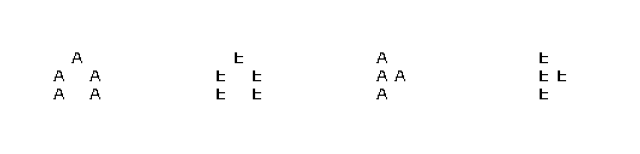

In [ ]:
# navon letters: global vs local distances per layer
from PIL import Image, ImageDraw, ImageFont
import matplotlib.font_manager as fm
FONT, LETTERS, GRID, CELL = fm.findfont('DejaVu Sans'), list('AEFHLOTUXZ'), 5, 15

def letter_mask(ch, size):
    f = ImageFont.truetype(FONT, int(size * 0.95)); im = Image.new('L', (size, size), 0); d = ImageDraw.Draw(im)
    l, t, r, b = d.textbbox((0, 0), ch, font=f)
    d.text(((size - (r - l)) / 2 - l, (size - (b - t)) / 2 - t), ch, fill=255, font=f)
    return np.array(im) > 127

def navon(g, l):                                       # global letter g made of local letters l, fits inside the mask circle
    cells = letter_mask(g, GRID * 10).reshape(GRID, 10, GRID, 10).mean((1, 3)) > 0.3
    lm, img, off = letter_mask(l, CELL), np.full((112, 112), 255, np.float32), (112 - GRID * CELL) // 2
    for i in range(GRID):
        for j in range(GRID):
            if cells[i, j]: img[off + i * CELL:off + (i + 1) * CELL, off + j * CELL:off + (j + 1) * CELL][lm] = 0
    return torch.tensor(img).expand(3, -1, -1).clone()

n = len(LETTERS)
NAV = torch.stack([navon(g, l) for g in LETTERS for l in LETTERS]).cuda()   # index = g*n + l
LAYERS = ['stem', 'stage1', 'stage2', 'stage3', 'stage4', 'embedding']

@torch.no_grad()
def layer_acts(m, x):
    if isinstance(m, C4ResNet18):
        h = m.stem(enn.GeometricTensor(F.interpolate(x.float(), size=EQ_SIZE, mode='bilinear', align_corners=False), m.tin)); out = [h.tensor]
        for i, b in enumerate(m.blocks):
            h = b(h)
            if i % 2 == 1: out.append(h.tensor)
        return out + [m.gpool(h).tensor.mean((2, 3))]
    h = m.maxpool(m.relu(m.bn1(m.conv1(x)))); out = [h]
    for L in (m.layer1, m.layer2, m.layer3, m.layer4): h = L(h); out.append(h)
    return out + [torch.flatten(m.avgpool(h), 1)]

gi = torch.tensor([(g1 * n + l, g2 * n + l) for l in range(n) for g1 in range(n) for g2 in range(g1 + 1, n)])
li = torch.tensor([(g * n + l1, g * n + l2) for g in range(n) for l1 in range(n) for l2 in range(l1 + 1, n)])
def gai(m, mode):
    res = []
    for A in layer_acts(m, prep(NAV, mode, False)):
        A = F.normalize(A.flatten(1).float() - A.flatten(1).float().mean(1, keepdim=True), dim=1); D = 1 - A @ A.T
        dG, dL = D[gi[:, 0], gi[:, 1]].mean().item(), D[li[:, 0], li[:, 1]].mean().item()
        res.append((dG - dL) / (dG + dL))             # > 0 global advantage, < 0 local advantage
    return res

gai_rows = {}
for mode in ['baseline', 'augmented', 'equivariant']:
    if os.path.exists(f'{CKPT}/{mode}.pt'):
        m = load(mode); gai_rows[mode] = gai(m, mode); del m; torch.cuda.empty_cache()
gai_df = pd.DataFrame(gai_rows, index=LAYERS).round(3)
gai_df.to_csv('/content/drive/MyDrive/face_inversion/gai_by_layer.csv'); display(gai_df)

fig, ax = plt.subplots(1, 4, figsize=(8, 2.2))                 # visual check of the Navon stimuli
for a, k in zip(ax, [0, 1, n, n + 1]): a.imshow(NAV[k].permute(1, 2, 0).byte().cpu()); a.axis('off')

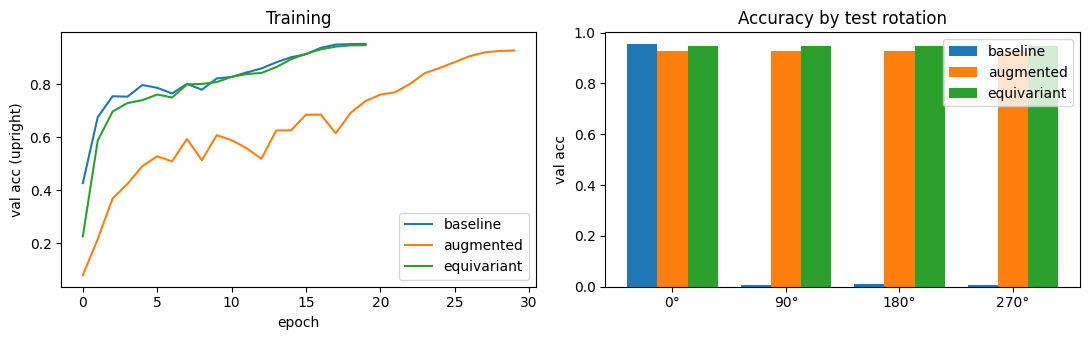

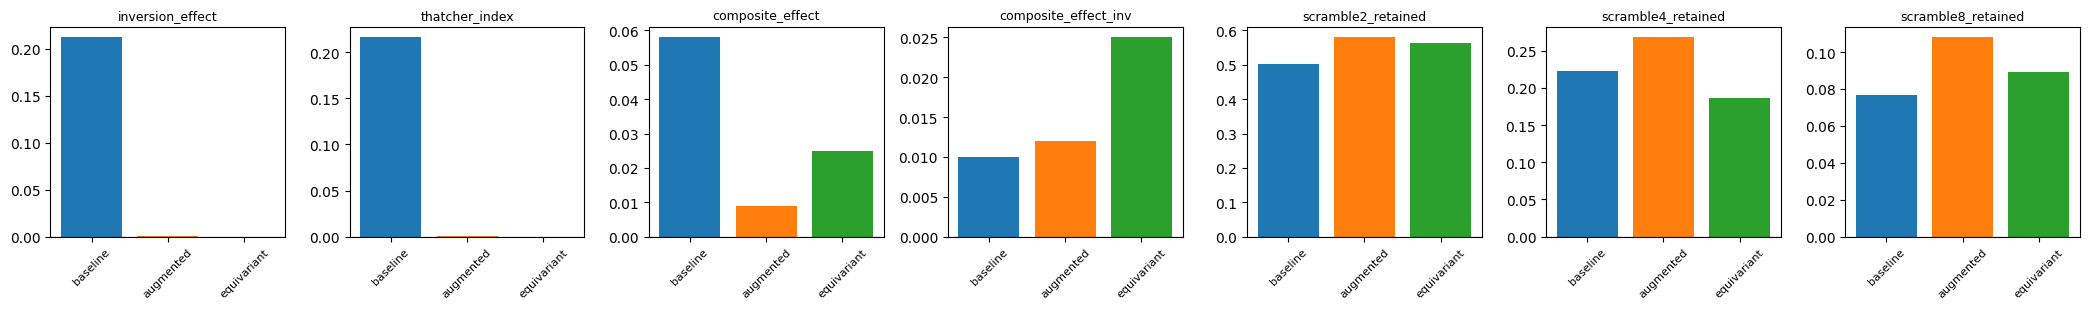

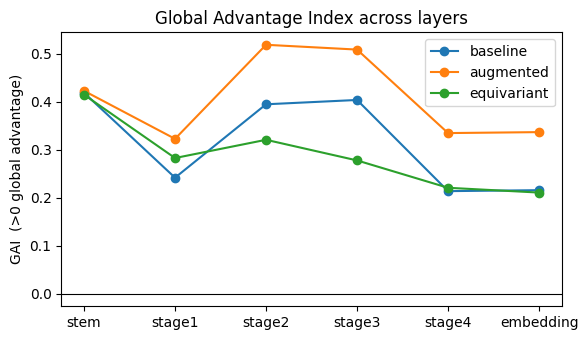

saved to /content/drive/MyDrive/face_inversion/figures


In [ ]:
# figures
FIG = '/content/drive/MyDrive/face_inversion/figures'; os.makedirs(FIG, exist_ok=True)
modes = [m for m in ['baseline', 'augmented', 'equivariant'] if os.path.exists(f'{CKPT}/{m}.pt')]
H = {m: torch.load(f'{CKPT}/{m}.pt', map_location='cpu', weights_only=False)['hist'] for m in modes}
res = pd.read_csv('/content/drive/MyDrive/face_inversion/holistic_results.csv', index_col=0)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for m in modes: ax[0].plot([h['val0'] for h in H[m]], label=m)
ax[0].set(xlabel='epoch', ylabel='val acc (upright)', title='Training'); ax[0].legend()
angs = [0, 90, 180, 270]; w = 0.8 / len(modes)
for i, m in enumerate(modes): ax[1].bar(np.arange(4) + i * w, [H[m][-1][f'val{a}'] for a in angs], w, label=m)
ax[1].set(xticks=np.arange(4) + w * (len(modes) - 1) / 2, xticklabels=[f'{a}°' for a in angs], ylabel='val acc', title='Accuracy by test rotation'); ax[1].legend()
plt.tight_layout(); plt.savefig(f'{FIG}/1_training_rotation.png', dpi=200); plt.show()

metrics = ['inversion_effect', 'thatcher_index', 'composite_effect', 'composite_effect_inv', 'scramble2_retained', 'scramble4_retained', 'scramble8_retained']
fig, ax = plt.subplots(1, len(metrics), figsize=(3 * len(metrics), 3.2))
for a, k in zip(ax, metrics):
    a.bar(res.index, res[k], color=['C0', 'C1', 'C2'][:len(res)]); a.axhline(0, color='k', lw=.8)
    a.set_title(k, fontsize=9); a.tick_params(axis='x', rotation=45, labelsize=8)
plt.tight_layout(); plt.savefig(f'{FIG}/2_holistic_signatures.png', dpi=200); plt.show()

ax = gai_df.plot(marker='o', figsize=(6, 3.5)); ax.axhline(0, color='k', lw=.8)
ax.set(ylabel='GAI  (>0 global advantage)', title='Global Advantage Index across layers')
plt.tight_layout(); plt.savefig(f'{FIG}/3_gai_layers.png', dpi=200); plt.show()
print('saved to', FIG)